In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("merged_hourly.csv")
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df
data=df.copy()


In [4]:
# # Sort chronologically within each city
# model_data = df.sort_values(
#     ["city", "Timestamp"]
# ).reset_index(drop=True)

# print("Model data shape:", model_data.shape)
# print(model_data.head())

In [5]:
print(df.shape)

(175392, 28)


In [6]:
df.head()

,city,site_id,Timestamp,PM2.5,PM10,NO,NO2,NOx,NH3,SO2,...,AT,RH,WS,WD,RF,TOT-RF,SR,BP,VWS,AQI
0,Banaras,273,2020-01-01 00:00:00,406.25,NaN,25.03,49.68,30.62,NaN,20.04,...,7.75,84.25,0.30,185.75,NaN,NaN,5.5,734.50,NaN,NaN
1,Banaras,273,2020-01-01 01:00:00,336.75,NaN,24.26,45.54,28.90,NaN,14.54,...,7.70,85.00,0.30,224.50,NaN,NaN,5.0,735.00,NaN,NaN
2,Banaras,273,2020-01-01 02:00:00,302.00,NaN,28.63,45.82,31.88,NaN,20.17,...,7.48,85.00,0.32,149.00,NaN,NaN,5.0,735.25,NaN,NaN
3,Banaras,273,2020-01-01 03:00:00,288.00,NaN,26.97,48.32,31.50,NaN,12.18,...,7.85,85.50,0.68,261.75,NaN,NaN,5.0,735.00,NaN,NaN
4,Banaras,273,2020-01-01 04:00:00,272.50,NaN,21.16,47.14,27.35,NaN,7.14,...,8.10,86.00,0.38,124.50,NaN,NaN,5.0,735.00,NaN,NaN


In [7]:
df.tail()

,city,site_id,Timestamp,PM2.5,PM10,NO,NO2,NOx,NH3,SO2,...,AT,RH,WS,WD,RF,TOT-RF,SR,BP,VWS,AQI
175387,Lucknow,5128,2024-12-31 19:00:00,50.25,59.50,1.80,5.05,6.35,NaN,8.87,...,16.48,74.25,0.90,232.25,0.0,0.0,6.00,NaN,-0.16,60.0
175388,Lucknow,5128,2024-12-31 20:00:00,45.25,54.25,1.80,5.00,6.30,NaN,8.70,...,16.40,74.00,0.95,238.00,0.0,0.0,6.00,NaN,-0.17,61.0
175389,Lucknow,5128,2024-12-31 21:00:00,44.50,53.25,1.80,5.00,6.30,NaN,8.63,...,16.30,74.00,0.82,240.25,0.0,0.0,5.00,NaN,-0.07,62.0
175390,Lucknow,5128,2024-12-31 22:00:00,44.25,53.00,1.80,5.00,6.28,NaN,8.25,...,16.15,73.00,1.08,233.25,0.0,0.0,4.75,NaN,-0.06,62.0
175391,Lucknow,5128,2024-12-31 23:00:00,42.00,50.00,1.77,4.90,6.17,NaN,7.83,...,15.90,74.67,0.67,299.33,0.0,0.0,4.33,NaN,-0.06,64.0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175392 entries, 0 to 175391
Data columns (total 28 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   city         175392 non-null  str           
 1   site_id      175392 non-null  int64         
 2   Timestamp    175392 non-null  datetime64[us]
 3   PM2.5        162744 non-null  float64       
 4   PM10         134697 non-null  float64       
 5   NO           154571 non-null  float64       
 6   NO2          159997 non-null  float64       
 7   NOx          160333 non-null  float64       
 8   NH3          67468 non-null   float64       
 9   SO2          153532 non-null  float64       
 10  CO           126489 non-null  float64       
 11  O3           163862 non-null  float64       
 12  Benzene      140799 non-null  float64       
 13  Toluene      140425 non-null  float64       
 14  Xylene       41441 non-null   float64       
 15  O Xylene     226 non-null     float64       


In [9]:
df.describe()

,site_id,Timestamp,PM2.5,PM10,NO,NO2,NOx,NH3,SO2,CO,...,AT,RH,WS,WD,RF,TOT-RF,SR,BP,VWS,AQI
count,175392.000000,175392,162744.000000,134697.000000,154571.000000,159997.000000,160333.000000,67468.000000,153532.000000,126489.000000,...,124861.000000,157234.000000,167173.000000,167156.000000,42248.000000,87696.000000,163287.000000,160583.000000,73881.000000,161450.000000
mean,1498.750000,2022-07-02 11:30:00,65.831856,143.634584,28.650470,38.810377,44.062887,30.112538,15.416819,1.192585,...,26.005543,64.897419,1.071176,180.533206,0.012507,0.017809,124.645835,788.105291,-0.323647,136.322806
min,273.000000,2020-01-01 00:00:00,0.010000,0.010000,0.010000,0.010000,0.000000,0.010000,0.010000,0.000000,...,0.100000,1.000000,0.010000,0.240000,0.000000,0.000000,0.010000,700.000000,-9.730000,12.000000
25%,288.000000,2021-04-01 17:45:00,22.500000,48.000000,2.980000,11.340000,9.520000,14.900000,7.033333,0.515000,...,20.700000,51.780625,0.350000,121.147500,0.000000,0.000000,6.890000,747.000000,-0.490000,60.000000
50%,297.000000,2022-07-02 11:30:00,41.550000,87.500000,6.330000,26.320000,17.720000,25.450000,12.800000,0.820000,...,26.600000,66.250000,0.775000,197.750000,0.000000,0.000000,13.750000,751.000000,-0.330000,99.000000
75%,1507.750000,2023-10-02 05:15:00,76.250000,180.500000,18.870000,52.420000,45.850000,41.680000,20.500000,1.525000,...,31.420000,79.000000,1.425000,235.000000,0.000000,0.000000,163.750000,757.625000,-0.160000,183.000000
max,5128.000000,2024-12-31 23:00:00,999.990000,1000.000000,499.500000,499.200000,500.000000,473.000000,199.640000,10.000000,...,49.900000,99.900000,16.270000,359.127500,49.000000,175.000000,1985.000000,999.900000,20.000000,500.000000
std,2095.379255,NaN,77.448905,149.833788,63.317119,39.506742,68.091612,21.602628,13.376781,1.089126,...,7.749957,18.132094,0.936530,75.465458,0.493644,1.028564,200.498534,85.092918,0.252284,103.924398


In [10]:
df.isna().sum()

city                0
site_id             0
Timestamp           0
PM2.5           12648
PM10            40695
NO              20821
NO2             15395
NOx             15059
NH3            107924
SO2             21860
CO              48903
O3              11530
Benzene         34593
Toluene         34967
Xylene         133951
O Xylene       175166
Eth-Benzene    151553
MP-Xylene      152594
AT              50531
RH              18158
WS               8219
WD               8236
RF             133144
TOT-RF          87696
SR              12105
BP              14809
VWS            101511
AQI             13942
dtype: int64

In [11]:
print(df["city"].value_counts())

city
Banaras    43848
Chennai    43848
Delhi      43848
Lucknow    43848
Name: count, dtype: int64


In [12]:
print("Date range:")
print(df["Timestamp"].min(), "to", df["Timestamp"].max())

Date range:
2020-01-01 00:00:00 to 2024-12-31 23:00:00


In [13]:
df.dtypes

city                      str
site_id                 int64
Timestamp      datetime64[us]
PM2.5                 float64
PM10                  float64
NO                    float64
NO2                   float64
NOx                   float64
NH3                   float64
SO2                   float64
CO                    float64
O3                    float64
Benzene               float64
Toluene               float64
Xylene                float64
O Xylene              float64
Eth-Benzene           float64
MP-Xylene             float64
AT                    float64
RH                    float64
WS                    float64
WD                    float64
RF                    float64
TOT-RF                float64
SR                    float64
BP                    float64
VWS                   float64
AQI                   float64
dtype: object

,Missing_Count,Missing_Percentage
O Xylene,175166,99.87
MP-Xylene,152594,87.00
Eth-Benzene,151553,86.41
Xylene,133951,76.37
RF,133144,75.91
NH3,107924,61.53
VWS,101511,57.88
TOT-RF,87696,50.00
AT,50531,28.81
CO,48903,27.88


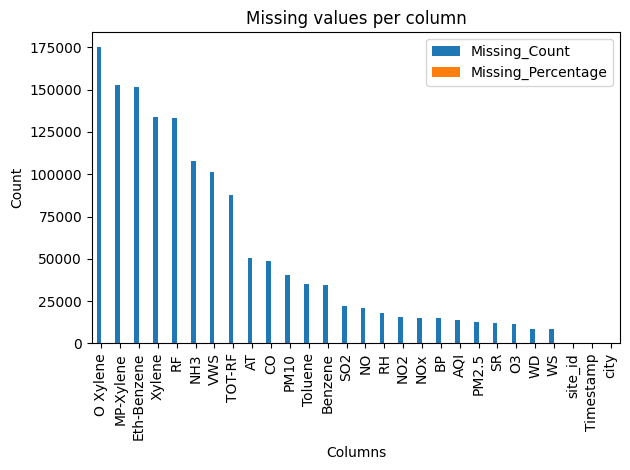

In [14]:
# Missing values in each column
missing = df.isna().sum().sort_values(ascending=False)

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

display(missing_report)

#plot
missing_report.plot(kind="bar")
plt.title("Missing values per column")
plt.xlabel("Columns")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [15]:
#duplicate records

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate city-timestamp pairs:",df.duplicated(subset=["city", "Timestamp"]).sum())

Exact duplicate rows: 0
Duplicate city-timestamp pairs: 0


In [16]:
print("Invalid timestamps:", df["Timestamp"].isna().sum())

Invalid timestamps: 0


In [17]:
#negative columns

pollutant_cols = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "SO2", "CO", "O3", "Benzene", "Toluene"
]

for col in pollutant_cols:
    if col in df.columns:
        print(f"{col}: {(df[col] < 0).sum()} negative values")

PM2.5: 0 negative values
PM10: 0 negative values
NO: 0 negative values
NO2: 0 negative values
NOx: 0 negative values
SO2: 0 negative values
CO: 0 negative values
O3: 0 negative values
Benzene: 0 negative values
Toluene: 0 negative values


In [18]:
#AQI by city

display(
    df.groupby("city")["AQI"].agg(
        Total="size",
        Available="count",
        Mean="mean",
        Min="min",
        Max="max"
    ).round(2)
)

# print("Minimum AQI:", df["AQI"].min())
# print("Maximum AQI:", df["AQI"].max())
# print("Negative AQI values:", (df["AQI"] < 0).sum())

,Total,Available,Mean,Min,Max
city,,,,,
Banaras,43848,42040,100.98,17.0,413.0
Chennai,43848,39754,86.54,12.0,342.0
Delhi,43848,37980,253.45,29.0,500.0
Lucknow,43848,41676,112.72,14.0,416.0


In [19]:
#remove missing AQI Rows

data.dropna(subset=["AQI"], inplace=True)
print("Shape:", data.shape)
print("Original shape: ", df.shape)

Shape: (161450, 28)
Original shape:  (175392, 28)


In [20]:
# fresh copy 
data = df.copy()

# drop unusable columns )
data = data.drop(columns=["O Xylene","MP-Xylene","Eth-Benzene","Xylene","RF","NH3","VWS","TOT-RF","AT","site_id"], errors="ignore")

# hourly -> daily average, keep days with at least 16 AQI hours
data["Date"] = data["Timestamp"].dt.floor("D")
g = data.groupby(["city","Date"])
daily_data = g.mean(numeric_only=True).reset_index()
daily_data["AQI_hours"] = g["AQI"].count().values
daily_data = daily_data[daily_data["AQI_hours"] >= 16].drop(columns="AQI_hours")

# fill missing values with each city's own median
cols = daily_data.columns.drop(["city","Date","AQI"])
daily_data[cols] = daily_data.groupby("city")[cols].transform(lambda s: s.fillna(s.median()))

print(daily_data.shape)                  
print(daily_data.isna().sum().sum())     


(6704, 18)
0


In [22]:
w = df[["city","Timestamp","WD"]].copy()
w["Date"] = w["Timestamp"].dt.floor("D")
w["WD_sin"] = np.sin(np.deg2rad(w["WD"]))
w["WD_cos"] = np.cos(np.deg2rad(w["WD"]))
wd_daily = w.groupby(["city","Date"])[["WD_sin","WD_cos"]].mean().reset_index()

daily_data = daily_data.drop(columns=["WD_sin","WD_cos"], errors="ignore").merge(wd_daily, on=["city","Date"], how="left")
for c in ["WD_sin","WD_cos"]:
    daily_data[c] = daily_data.groupby("city")[c].transform(lambda s: s.fillna(s.median()))

print(daily_data.shape, daily_data.isna().sum().sum())    

(6704, 20) 0


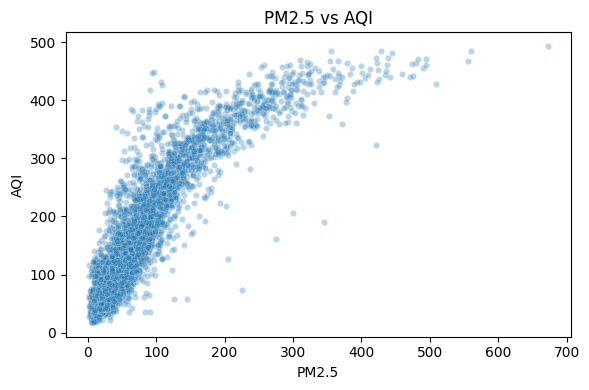

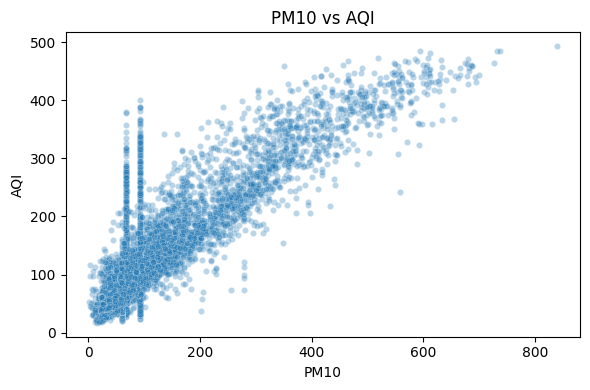

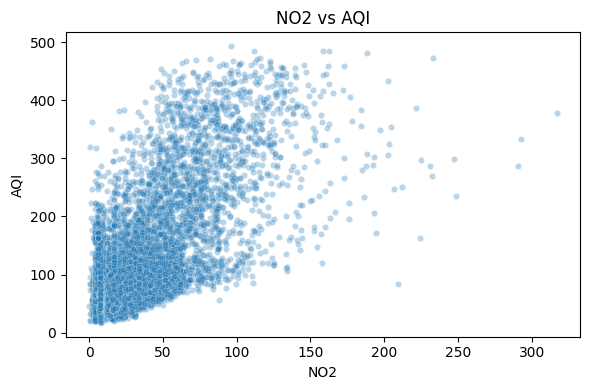

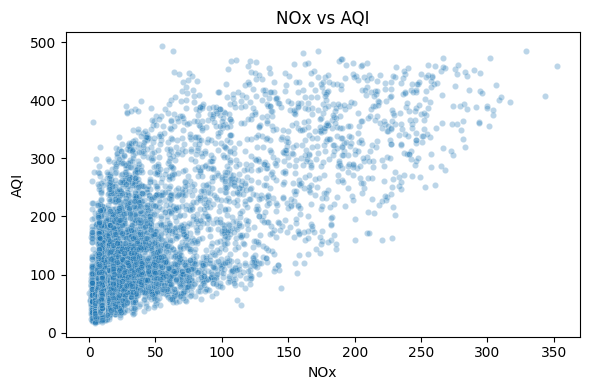

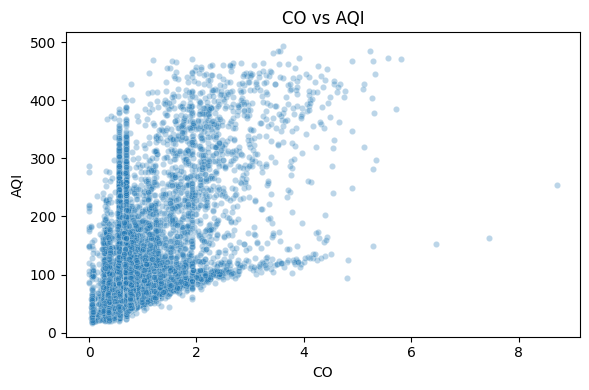

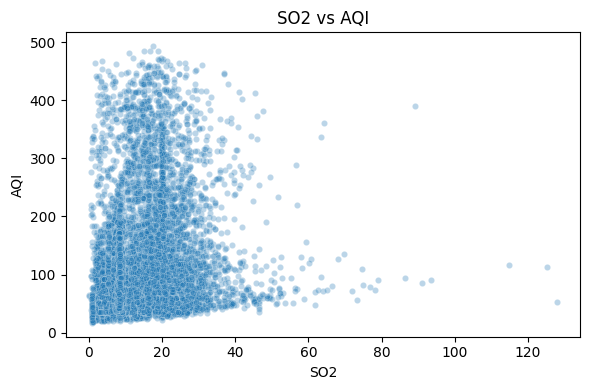

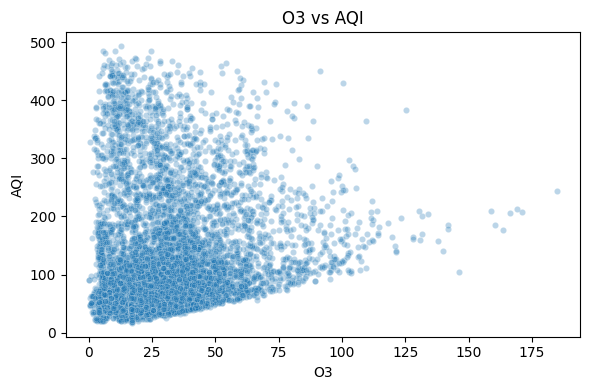

In [25]:
features = ["PM2.5", "PM10", "NO2", "NOx", "CO", "SO2", "O3"]

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(
        data=daily_data,
        x=feature,
        y="AQI",
        alpha=0.3,
        s=20
    )
    plt.title(f"{feature} vs AQI")
    plt.xlabel(feature)
    plt.ylabel("AQI")
    plt.tight_layout()
    plt.show()

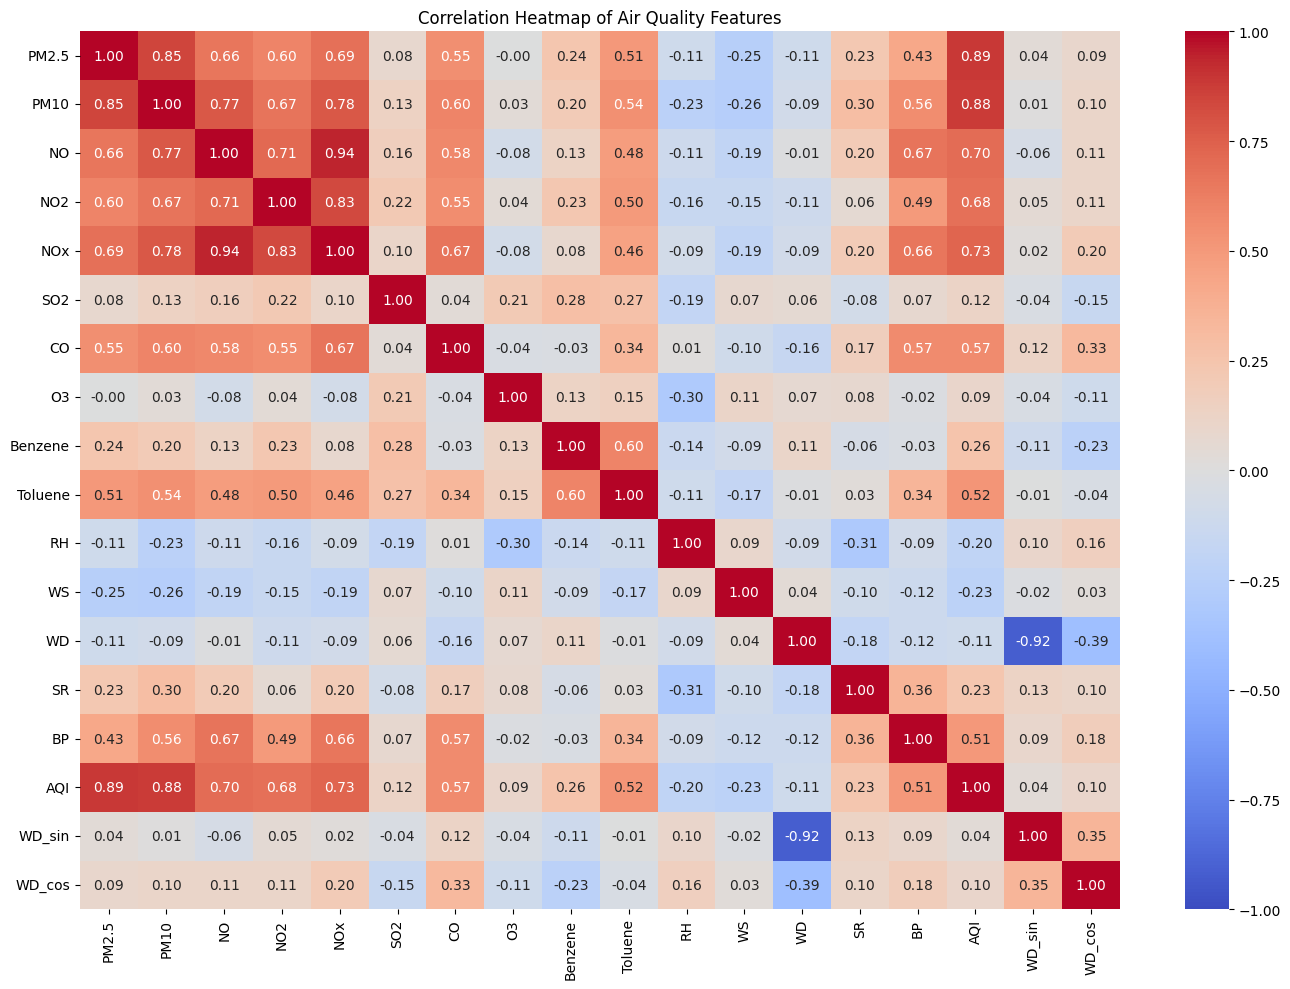

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns
numeric_data = daily_data.select_dtypes(include="number")

# Calculate correlations
corr = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Air Quality Features")
plt.tight_layout()
plt.show()

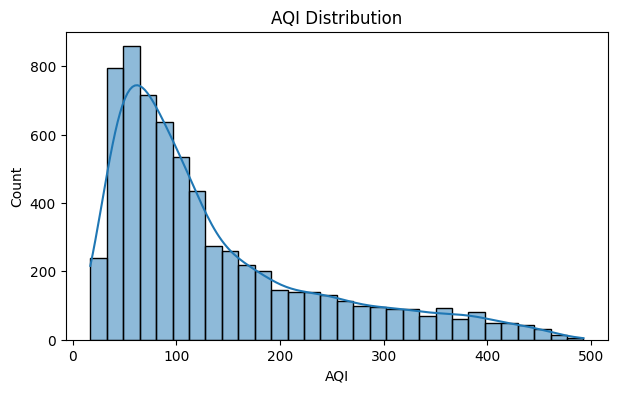

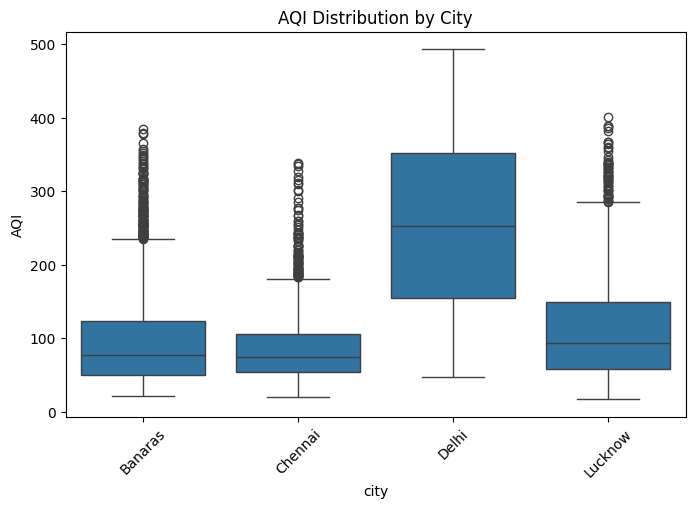

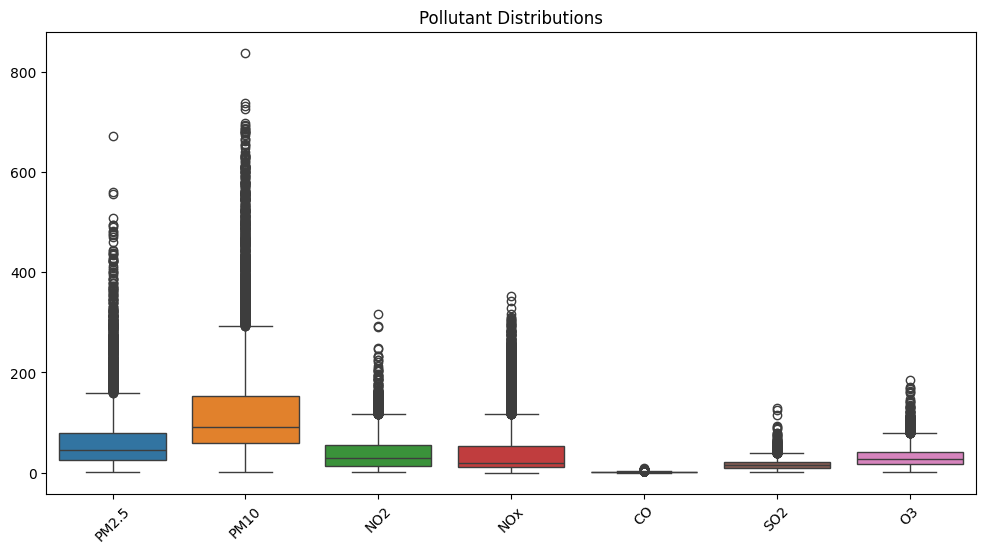

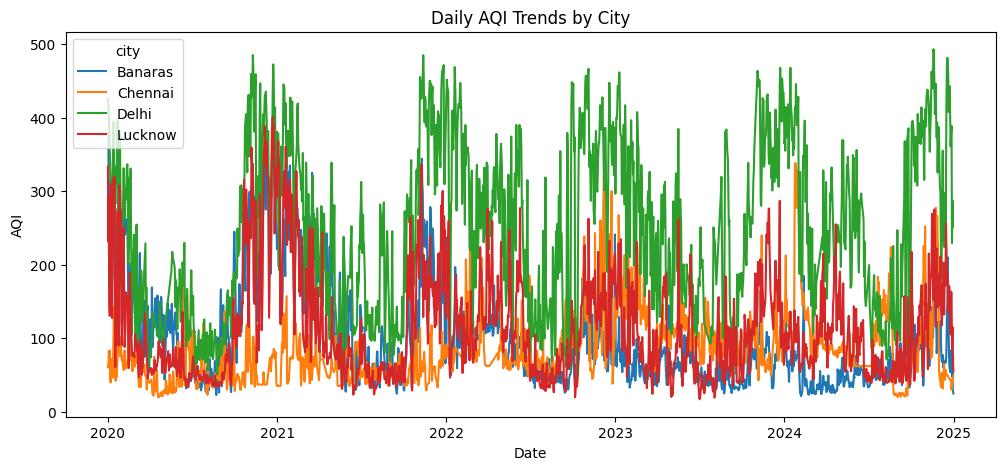

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. AQI distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=daily_data, x="AQI", bins=30, kde=True)
plt.title("AQI Distribution")
plt.show()

# 2. AQI comparison across cities
plt.figure(figsize=(8, 5))
sns.boxplot(data=daily_data, x="city", y="AQI")
plt.title("AQI Distribution by City")
plt.xticks(rotation=45)
plt.show()

# 3. Pollutant distributions
pollutants = ["PM2.5", "PM10", "NO2", "NOx", "CO", "SO2", "O3"]

plt.figure(figsize=(12, 6))
sns.boxplot(data=daily_data[pollutants])
plt.title("Pollutant Distributions")
plt.xticks(rotation=45)
plt.show()

# 4. AQI trend over time by city
plt.figure(figsize=(12, 5))
sns.lineplot(data=daily_data, x="Date", y="AQI", hue="city")
plt.title("Daily AQI Trends by City")
plt.show()

In [30]:
daily_data.isna().sum().sum()

np.int64(0)

In [38]:
# Features to check for outliers
check = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "SO2", "CO", "O3",
    "Benzene", "Toluene", "RH", "WS", "SR", "BP", "AQI"
]

rows = []

# Check each feature separately
for col in check:
    # Calculate first and third quartiles
    q1, q3 = daily_data[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    # Count values outside the IQR boundaries
    n = (
        (daily_data[col] < q1 - 1.5 * iqr) |
        (daily_data[col] > q3 + 1.5 * iqr)
    ).sum()

    # Store outlier count and percentage
    rows.append({
        "Feature": col,
        "Outliers": n,
        "% of days": round(100 * n / len(daily_data), 1)
    })

# Display features with the most outliers first
pd.DataFrame(rows).sort_values("Outliers", ascending=False)

,Feature,Outliers,% of days
13,BP,1307,19.5
2,NO,1051,15.7
1,PM10,769,11.5
4,NOx,735,11.0
8,Benzene,666,9.9
9,Toluene,559,8.3
0,PM2.5,538,8.0
6,CO,414,6.2
14,AQI,367,5.5
11,WS,252,3.8


In [31]:
# Remove raw wind direction (circular feature)
daily_data.drop(columns=["WD"], inplace=True, errors="ignore")

# Add calendar features
daily_data["Month"] = daily_data["Date"].dt.month
daily_data["DayOfWeek"] = daily_data["Date"].dt.dayofweek

In [32]:
daily_data = daily_data.sort_values(["city", "Date"]).reset_index(drop=True)

daily_data["next_date"] = daily_data.groupby("city")["Date"].shift(-1)
daily_data["AQI_next"] = daily_data.groupby("city")["AQI"].shift(-1)

daily_data.loc[
    (daily_data["next_date"] - daily_data["Date"]).dt.days != 1,
    "AQI_next"
] = np.nan

model_data = daily_data.dropna(subset=["AQI_next"]).drop(columns="next_date").copy()

print(model_data.shape)

(6405, 22)


In [39]:
from sklearn.preprocessing import StandardScaler

# 1. Split data by date
train = model_data[model_data["Date"] < "2024-01-01"].copy()
test = model_data[model_data["Date"] >= "2024-01-01"].copy()

# Separate features and target
X_train = train.drop(columns=["Date", "AQI_next"])
y_train = train["AQI_next"]

X_test = test.drop(columns=["Date", "AQI_next"])
y_test = test["AQI_next"]

# 2. One-hot encode city
X_train = pd.get_dummies(X_train, columns=["city"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["city"], dtype=int)

# Match test columns to training columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 3. Cap extreme predictor values using training quantiles
cap_cols = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "SO2", "CO", "O3",
    "Benzene", "Toluene", "RH", "WS", "SR", "BP"
]

lower = X_train[cap_cols].quantile(0.005)
upper = X_train[cap_cols].quantile(0.995)

X_train[cap_cols] = X_train[cap_cols].clip(lower, upper, axis=1)
X_test[cap_cols] = X_test[cap_cols].clip(lower, upper, axis=1)

# 4. Standardize numeric features only
num_cols = [c for c in X_train.columns if not c.startswith("city_")]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# 5. Check dataset sizes
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5097, 23)
Testing shape: (1308, 23)


In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

# Define the models
lr = LinearRegression()
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
dt = DecisionTreeRegressor(random_state=42)
gb = GradientBoostingRegressor(random_state=42)

# Train the models
lr.fit(X_train, y_train)
rf.fit(X_train, y_train)
dt.fit(X_train, y_train)
gb.fit(X_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [ ]:
git init -y


In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate predictions
predictions = {
    "Linear Regression": lr.predict(X_test),
    "Random Forest": rf.predict(X_test),
    "Decision Tree": dt.predict(X_test),
    "Gradient Boosting": gb.predict(X_test)
}

# Evaluate each model
results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": round(mean_absolute_error(y_test, pred), 2),
        "RMSE": round(mean_squared_error(y_test, pred) ** 0.5, 2),
        "R2": round(r2_score(y_test, pred), 3)
    })

# Display results, sorted by RMSE
results_df = pd.DataFrame(results).sort_values("RMSE")
results_df

,Model,MAE,RMSE,R2
1,Random Forest,16.16,24.27,0.946
3,Gradient Boosting,17.43,25.19,0.942
0,Linear Regression,19.86,29.39,0.920
2,Decision Tree,24.04,35.76,0.882
